# Details of the randomized Hamiltonian simulation proposal

$\renewcommand{\ket}[1]{\left|#1\right\rangle}\renewcommand{\bra}[1]{\left\langle #1\right|}\renewcommand{\braket}[2]{\left\langle #1 \middle| #2 \right\rangle}\renewcommand{\ketbra}[2]{\left|#1\right\rangle\!\left\langle #2\right|}$This notebook illustrates the details of implementing the randomized Hamiltonian simulation proposal. This is obtained by averaging the transition probabilities generated by the transverse-field Hamiltonian over a range of evolution times $t$ and transverse-field strengths $\gamma$.

**Table of contents**

1. [Imports](#imports)
2. [The randomized construction](#randomized-construction)
3. [Range of choice for the parameters](#parameter-range)
5. [Discretization of the randomized construction](#discretization)
4. [Comparison with a fixed choice of $(t,\gamma)$](#fixed-choice)


## Imports<a id="imports"></a>

In [1]:
import sys

if ".." not in sys.path:
    sys.path.append("..")
    
import json
import matplotlib.pyplot as plt
import numpy as np
from monaqa2.data.filename import CONVERGENCE_RANDOMIZED_HYPERPARAMS_FILE, GRIDSEARCH_RANDOMIZED_HYPERPARAMS_FILE
from monaqa2.data.instances import load_instances
from monaqa2.mcmc.proposal import create_proposal_matrix_quantum_exact, create_proposal_matrix_quantum_layden
from monaqa2.mcmc.transition import create_transition_matrix
from monaqa2.mcmc.model import IsingModel

## The randomized construction

<a id="randomized-construction"></a>Let $H$ be the Ising Hamiltonian and $H_{\mathrm{mix}}$ is the transverse field mixer. The transverse field Hamiltonian with fransverse field strangth $\gamma$ is defined as $H_{\mathrm{tf}} = H+\gamma H_{\mathrm{mix}}$. 

For a single fixed choice of $(t,\gamma)$, the Hamiltonian simulation induces the trial proposal

$$
T_{yx}(t,\gamma)
=
\left|
\bra{y}e^{-itH_{\mathrm{tf}}(\gamma)}\ket{x}
\right|^2.
$$

Rather than selecting a single pair $(t,\gamma)$, the randomized construction averages these transition probabilities over prescribed parameter ranges,

$$
\overline T_{yx}
=
\frac{1}{(t_1-t_0)(\gamma_1-\gamma_0)}
\int_{t_0}^{t_1}dt
\int_{\gamma_0}^{\gamma_1}d\gamma\,
T_{yx}(t,\gamma).
$$

This averaging defines one trial proposal matrix $\overline T$. The corresponding Metropolis transition matrix $\overline P$ is then obtained by applying the usual acceptance rule at inverse temperature $\beta$.

While actually an instance-specific optimization of the hyper-parameters,
$$(t^*, \gamma^*) = \arg\max...$$
can potentially lead to better spectral gaps, such a procedure is expensive; Ref [1] and [2] have already shown the randomized approach gives comparable performances without the need of any optimization. 

In our implementation, the method `create_proposal_matrix_quantum_layden` is used as the numerical reference to create $\bar T$. The time average is evaluated analytically after diagonalizing $H_{\mathrm{tf}}(\gamma)$, whereas the $\gamma$ integral is represented by 20 equally spaced midpoint values. Thus, throughout this notebook, *reference randomized proposal* means a continuous average in $t$ together with a 20-point discretization in $\gamma$ used by the software.

## Range of choice for the parameters

<a id="parameter-range"></a>We use the parameter ranges

$$
t\in[2,20],
\qquad
\gamma\in[0.25,0.60],
$$




The role of the two parameters is different. The transverse-field strength $\gamma$ controls the balance between the problem Hamiltonian and the mixer. For very small $\gamma$, the dynamics approaches a perturbative regime in which the dominant transitions resemble local spin flips. For very large $\gamma$, the mixer dominates and the proposal progressively loses information about the energy landscape. The useful regime is therefore intermediate; subsequent numerical studies find a broad region of good performance around $\gamma\simeq0.3$--$0.5$, rather than a sharply tuned optimum.

The evolution time $t$ controls how far the state evolves under the transverse-field Hamiltonian. Very short evolution times produce only weak transitions. As $t$ increases, the proposal rapidly develops non-local structure and its performance reaches a broad fluctuating plateau, so extending the evolution indefinitely is not expected to provide a systematic advantage. The interval $[2,20]$ therefore samples this developed dynamical regime while avoiding both the short-time limit and unnecessarily long evolutions.

The endpoints should not be interpreted as mathematically optimal constants. They define a robust parameter domain over which the randomized proposal is averaged.

For the numerical experiments below we therefore fix:


In [2]:
BETA = 4.0
TIME_LIMS = (2.0, 20.0)
GAMMA_LIMS = (0.25, 0.60)

NS = range(3, 9 + 1)
IDXS = range(100)
KS = range(1, 6)

## Discretization of the randomized construction

<a id="discretization"></a>The randomized average cannot be implemented coherently by sampling a continuous parameter domain directly. We therefore approximate it by a finite set of Hamiltonian-simulation unitaries.

For a discretization level $k$, let

$$
N_t=2^k,
\qquad
N_\gamma=\min(2^k,20),
\qquad
M=N_tN_\gamma.
$$

Using equally spaced midpoint values $t_j\in[2,20]$ and $\gamma_\ell\in[0.25,0.60]$, we define

$$
\overline T^{(k)}_{yx}
=
\frac{1}{M}
\sum_{j=0}^{N_t-1}
\sum_{\ell=0}^{N_\gamma-1}
\left|
\bra{y}
e^{-it_jH_{\mathrm{tf}}(\gamma_\ell)}
\ket{x}
\right|^2.
$$

Both grids are refined with increasing $k$ until $N_\gamma=20$, matching the $\gamma$ resolution of the reference implementation. Beyond that point only the time grid is further refined.

For a coherent quantum implementation, the same finite average can be generated using a uniform superposition over the $M$ parameter labels and a controlled `SELECT` operation applying the corresponding Hamiltonian-simulation unitary. The numerical calculation below constructs the resulting classical proposal matrix directly.


In [7]:
def get_spectral_gap(Q_: np.ndarray) -> float:
    evals = np.linalg.eigvalsh(np.sqrt(np.maximum(Q_ * Q_.T, 0.0)))
    return float(1.0 - np.max(np.abs(evals[:-1])))

# The code below has been already executed and the results are in 
# /data/convergence_randomized_hyperparams.json
# If you want to launch it, do that in parallel because it takes waaaay to much
# time to calculate everything sequentially, check /robustness_randomized_proposal
# subfolder for more info on this

if CONVERGENCE_RANDOMIZED_HYPERPARAMS_FILE.exists():
    with open(CONVERGENCE_RANDOMIZED_HYPERPARAMS_FILE) as f:
        spectral_gaps = json.load(f)
else:
    spectral_gaps = {}

# APPROACHES = (
#     ["T_exact"]
#     + [f"T_grid_k{k}" for k in KS]
#     + ["P_exact"]
#     + [f"P_grid_k{k}" for k in KS]
# )
# 
# for approach in APPROACHES:
#     spectral_gaps.setdefault(
#         approach, [[None] * len(IDXS) for _ in NS]
#     )
# 
# 
# # Reference randomized proposal:
# # continuous time average and 20 gamma midpoint values.
# for n in NS:
#     print(f"\nn={n}: ", end="")
# 
#     for idx in IDXS:
#         i = n - NS.start
# 
#         if (
#             spectral_gaps["T_exact"][i][idx] is not None
#             and spectral_gaps["P_exact"][i][idx] is not None
#         ):
#             continue
# 
#         print(".", end="")
# 
#         ising = load_instances(n, idx)
#         T = create_proposal_matrix_quantum_layden(
#             ising.h_rescaled,
#             ising.J_rescaled,
#             gamma_lims=GAMMA_LIMS,
#             gamma_steps=20,
#             time_lims=TIME_LIMS,
#         )
# 
#         spectral_gaps["T_exact"][i][idx] = get_spectral_gap(T)
#         spectral_gaps["P_exact"][i][idx] = get_spectral_gap(
#             create_transition_matrix(T, ising, BETA)
#         )
# 
#         # Save after every instance so interrupted calculations can resume.
#         with open(CONVERGENCE_RANDOMIZED_HYPERPARAMS_FILE, "w") as f:
#             json.dump(spectral_gaps, f)
# 
# 
# # Finite-grid approximation:
# # discrete midpoint grids for both t and gamma.
# for k in KS:
#     nt = 2**k
#     ng = min(2**k, 20)
# 
#     t0, t1 = TIME_LIMS
#     g0, g1 = GAMMA_LIMS
# 
#     times = t0 + (np.arange(nt) + 0.5) * (t1 - t0) / nt
#     gammas = g0 + (np.arange(ng) + 0.5) * (g1 - g0) / ng
# 
#     for n in NS:
#         print(f"\nk={k} n={n}: ", end="")
# 
#         for idx in IDXS:
#             i = n - NS.start
#             T_key = f"T_grid_k{k}"
#             P_key = f"P_grid_k{k}"
# 
#             if (
#                 spectral_gaps[T_key][i][idx] is not None
#                 and spectral_gaps[P_key][i][idx] is not None
#             ):
#                 continue
# 
#             print(".", end="")
# 
#             ising = load_instances(n, idx)
#             T = np.zeros((2**n, 2**n))
# 
#             for t in times:
#                 for gamma in gammas:
#                     T += create_proposal_matrix_quantum_exact(
#                         ising.h_rescaled,
#                         ising.J_rescaled,
#                         gamma,
#                         t,
#                     )
# 
#             T /= nt * ng
# 
#             spectral_gaps[T_key][i][idx] = get_spectral_gap(T)
#             spectral_gaps[P_key][i][idx] = get_spectral_gap(
#                 create_transition_matrix(T, ising, BETA)
#             )
# 
#             with open(CONVERGENCE_RANDOMIZED_HYPERPARAMS_FILE, "w") as f:
#                 json.dump(spectral_gaps, f)

We finally verify that refining the finite parameter grid reproduces the reference randomized construction.

The most relevant quantity for the Monte Carlo algorithm is the spectral gap of the Metropolis transition matrix. We therefore compare

$$
\delta\!\left(\overline P^{(k)}\right)
\quad\text{with}\quad
\delta\!\left(\overline P\right)
$$

as a function of the system size $n$ and discretization level $k$.

For each $n$, the marker indicates the median spectral gap over the considered Ising instances, while the whiskers show the interquartile range. As $k$ increases, the finite-grid results should approach the reference randomized proposal. The same comparison can also be performed directly at the level of the trial proposal matrix $T$.


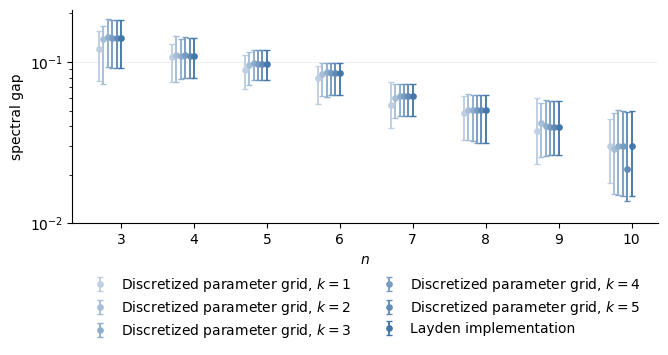

In [8]:
from monaqa2.data.plot_aux import plot_spectral_gaps_randomized_subset_parameters
plot_spectral_gaps_randomized_subset_parameters(spectral_gaps, is_transition=True)
plt.savefig("plots/2_randomized_grid_params_spectral_gaps.png", dpi=300, bbox_inches="tight")

## Comparison with a fixed choice of $(t,\gamma)$

<a id="fixed-choice"></a>A natural question is whether the randomized construction can be replaced by one fixed pair $(t^\star,\gamma^\star)$.

In general, there is no reason for a single pair to reproduce the averaged proposal exactly:

$$
T(t^\star,\gamma^\star)
\neq
\overline T
$$

in general. The averaging is performed element by element over the full matrix $T(t,\gamma)$, and a pair reproducing the average of one matrix element need not reproduce the averages of the others.

A fixed pair can nevertheless be useful as a benchmark. We may search over the same parameter domain and select the pair maximizing a chosen performance measure, for example the spectral gap of the resulting Metropolis transition matrix,

$$
(t^\star,\gamma^\star)
=
\arg\max_{(t,\gamma)}
\delta\!\left(P(t,\gamma)\right).
$$

This tests whether randomization itself is useful, or whether comparable performance can be obtained from a single well-chosen Hamiltonian evolution. It also gives a simpler quantum implementation because no parameter register or coherent selection over several Hamiltonian simulation unitaries is required.

In [9]:
# The code for this analysis has been run and results are in
# data/gridsearch_randomized_hyperparams.json
# These contains, for a grid of k=3 (i.e. 2^3 values of t, and 2^3 
# values of gamma in the range given by Laiden et al), a total of
# M = 2^k * min(20, 2^k) = 64 parameter choices. 
# If you want to launch it, do that in parallel because it takes waaaay to much
# time to calculate everything sequentially, check /robustness_randomized_proposal
# subfolder for more info on this.

(<Figure size 677.165x330.709 with 1 Axes>,
 <Axes: xlabel='$n$', ylabel='$\\log(\\delta_{\\mathrm{grid}}/\\delta_{\\mathrm{avg}})$'>)

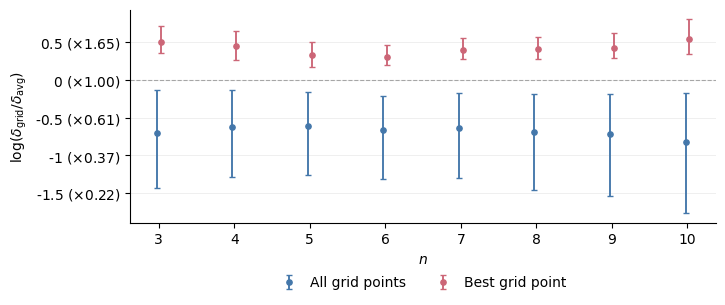

In [23]:
from pathlib import Path
from monaqa2.data.filename import CONVERGENCE_RANDOMIZED_HYPERPARAMS_FILE, GRIDSEARCH_RANDOMIZED_HYPERPARAMS_FILE
from monaqa2.data.plot_aux_updated_4 import plot_randomized_grid_search_difference

grid_search_file = Path(GRIDSEARCH_RANDOMIZED_HYPERPARAMS_FILE)
averaged_matrix_file = Path(CONVERGENCE_RANDOMIZED_HYPERPARAMS_FILE)

plot_randomized_grid_search_difference(
    grid_search_file,
    averaged_matrix_file,
    k=3,
    output_file="plots/3_randomized_grid_search_difference.png",
)